<a href="https://colab.research.google.com/github/hidrofluorik/Dataset-Google-Play-Store-Apps/blob/main/Tugas_Kelompok_K_Means_PlayStore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

# Load the googleplaystore dataset
df = pd.read_csv('/content/googleplaystores.csv')
print("Dataset loaded successfully with shape:", df.shape)

Dataset loaded successfully with shape: (10841, 3)


In [ ]:
print("=== Jumlah Nilai Kosong per Kolom ===")
print(df.isnull().sum())
print("\nTotal Nilai Kosong Keseluruhan:", df.isnull().sum().sum())
print("\n=== Jumlah Baris Duplikat ===")
print("Total Baris Duplikat:", df.duplicated().sum())

=== Jumlah Nilai Kosong per Kolom ===
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Total Nilai Kosong Keseluruhan: 1487

=== Jumlah Baris Duplikat ===
Total Baris Duplikat: 483


### Pembersihan Dataset (Data Cleaning)

Langkah-langkah yang akan dilakukan:
1. Menghapus baris duplikat.
2. Menangani nilai kosong pada kolom `Rating` (misalnya dengan nilai median atau mean, atau menghapusnya jika diperlukan).
3. Menangani nilai kosong pada kolom lainnya seperti `Type`, `Content Rating`, `Current Ver`, dan `Android Ver`.

In [6]:
import pandas as pd

# Membaca dataset
df = pd.read_csv('/content/googleplaystores.csv')

# Memastikan nama kolom bersih dari spasi
df.columns = df.columns.str.strip()

print("Kolom yang terdeteksi di dalam file:", list(df.columns))

# 1. Menghapus baris duplikat
df_clean = df.drop_duplicates().copy()

# 2. Mengisi nilai kosong pada kolom 'Rating' jika kolom tersebut ada
if 'Rating' in df_clean.columns:
    median_rating = df_clean['Rating'].median()
    df_clean['Rating'] = df_clean['Rating'].fillna(median_rating)

# 3. Menghapus baris yang memiliki nilai kosong di kolom lainnya jika tersedia
columns_to_check = [col for col in ['Type', 'Content Rating', 'Current Ver', 'Android Ver'] if col in df_clean.columns]
if columns_to_check:
    df_clean = df_clean.dropna(subset=columns_to_check)

# Menampilkan hasil pembersihan
print("\n=== Setelah Pembersihan ===")
print("Ukuran dataset baru:", df_clean.shape)
print("Jumlah nilai kosong per kolom:\n", df_clean.isnull().sum())
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

Kolom yang terdeteksi di dalam file: ['Rating', 'Reviews', 'Installs']

=== Setelah Pembersihan ===
Ukuran dataset baru: (8552, 3)
Jumlah nilai kosong per kolom:
 Rating      0
Reviews     0
Installs    0
dtype: int64
Jumlah baris duplikat: 41


### Menghitung Korelasi antara Rating dan Reviews

Sebelum menghitung korelasi, kita perlu memastikan tipe data kedua kolom tersebut adalah numerik.

In [7]:
# Persiapan Data untuk K-Means (Fokus: Aplikasi Berkualitas)
import pandas as pd
import numpy as np
df_kmeans = df_clean.copy()

# Ubah Rating dan Reviews menjadi numerik.
df_kmeans['Rating'] = pd.to_numeric(df_kmeans['Rating'], errors='coerce')
df_kmeans['Reviews'] = pd.to_numeric(df_kmeans['Reviews'], errors='coerce')

# Bersihkan Installs: hapus tanda koma dan tanda tambah, lalu ubah menjadi numerik.
df_kmeans['Installs'] = (
    df_kmeans['Installs'].astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)
df_kmeans['Installs'] = pd.to_numeric(df_kmeans['Installs'], errors='coerce')

# Rating yang lebih dari 5 merupakan data tidak valid.
df_kmeans.loc[df_kmeans['Rating'] > 5, 'Rating'] = np.nan

# Ambil hanya fitur yang digunakan dan hapus baris yang masih memiliki nilai kosong.
fitur = ['Rating', 'Reviews', 'Installs']
df_kmeans = df_kmeans[fitur].dropna().copy()

print('Jumlah data setelah preprocessing:', df_kmeans.shape[0])
print('\nCek nilai kosong:')
print(df_kmeans.isnull().sum())
print('\nStatistik deskriptif:')
display(df_kmeans.describe())

# Reviews dan Installs memiliki rentang nilai yang sangat besar,
# sehingga digunakan transformasi log1p untuk mengurangi kemencengan distribusi.
df_kmeans_transform = df_kmeans.copy()
df_kmeans_transform['Reviews'] = np.log1p(df_kmeans_transform['Reviews'])
df_kmeans_transform['Installs'] = np.log1p(df_kmeans_transform['Installs'])

print('\nData setelah transformasi log1p:')
display(df_kmeans_transform.head())


Jumlah data setelah preprocessing: 8551

Cek nilai kosong:
Rating      0
Reviews     0
Installs    0
dtype: int64

Statistik deskriptif:


,Rating,Reviews,Installs
count,8551.000000,8.551000e+03,8.551000e+03
mean,4.176471,4.910435e+05,1.713021e+07
std,0.499181,2.960557e+06,8.801398e+07
min,1.000000,0.000000e+00,0.000000e+00
25%,4.000000,2.375000e+02,1.000000e+04
50%,4.300000,6.090000e+03,5.000000e+05
75%,4.500000,7.913100e+04,5.000000e+06
max,5.000000,7.815831e+07,1.000000e+09



Data setelah transformasi log1p:


,Rating,Reviews,Installs
0,4.1,5.075174,9.210440
1,3.9,6.875232,13.122365
2,4.7,11.379520,15.424949
3,4.5,12.281389,17.727534
4,4.3,6.875232,11.512935


# Standardisasi Fitur
Setelah transformasi logaritma, ketiga fitur perlu distandardisasi agar memiliki skala yang sebanding. Standardisasi dilakukan sebelum K-Means karena algoritma ini menggunakan jarak antar data.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans_transform[fitur])

print("Ukuran data setelah standardisasi:", X_scaled.shape)
print("Rata-rata setiap fitur:", X_scaled.mean(axis=0).round(3))
print("Standar deviasi setiap fitur:", X_scaled.std(axis=0).round(3))


Ukuran data setelah standardisasi: (8551, 3)
Rata-rata setiap fitur: [-0.  0. -0.]
Standar deviasi setiap fitur: [1. 1. 1.]


# Menentukan Jumlah Cluster dengan Elbow Method
Elbow Method dijalankan untuk nilai K dari 2 sampai 10. Nilai inertia (Within-Cluster Sum of Squares) dicatat pada setiap K. Semakin kecil inertia, semakin dekat data di dalam cluster. Namun, inertia akan terus menurun ketika jumlah cluster bertambah, sehingga jumlah K dipilih dari titik ketika penurunan inertia mulai melandai.

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Tabel nilai inertia untuk setiap K
elbow_results = pd.DataFrame({
    'Jumlah Cluster (K)': list(k_values),
    'Inertia': inertia_values
})

display(elbow_results)


,Jumlah Cluster (K),Inertia
0,2,13289.133282
1,3,9071.733964
2,4,6870.086243
3,5,5774.120696
4,6,4922.431762
5,7,4265.377370
6,8,3838.029504
7,9,3458.772992
8,10,3133.369486


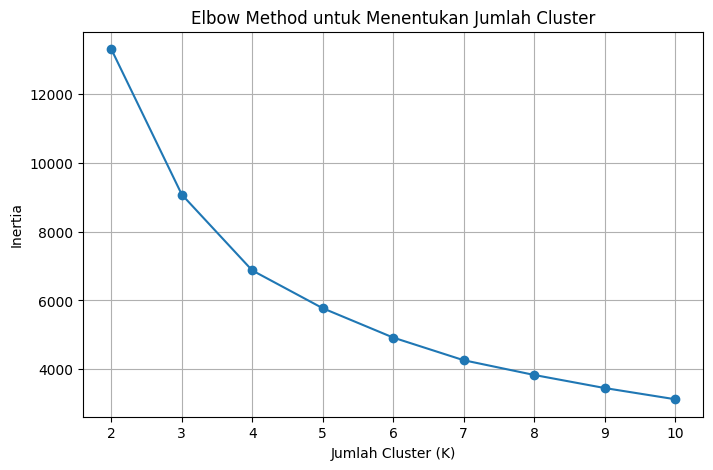

In [10]:
# Visualisasi Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.title('Elbow Method untuk Menentukan Jumlah Cluster')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


# Analisis Hasil Elbow Method
Amati grafik dan cari titik yang membentuk siku (elbow), yaitu saat penurunan inertia yang awalnya tajam mulai melandai. Titik tersebut menjadi kandidat jumlah cluster yang efisien.

# Kesimpulan Sementara
Berdasarkan grafik Elbow Method, kita dapat menentukan jumlah cluster (K) yang paling sesuai dari titik siku pada grafik. Hasil ini nantinya akan dibandingkan dengan Silhouette Score untuk mendapatkan jumlah cluster yang tepat. Setelah itu, setiap cluster akan dilihat karakteristiknya untuk mengetahui kelompok aplikasi yang berkualitas.